# LungCT COPD Mask Inspection

Run this notebook in the project environment with `INRORSPLINE_REPO_ROOT` and `LUNGCT_DIRLAB_ROOT` configured.

This notebook stages paired COPD `iBH` and `eBH` lung masks with `lungmask R231`, verifies the native image/mask/landmark geometry for cases 01–10, and renders coronal QA overlays using the same radiology-orientation convention as the 4DCT visual audits: superior at top, inferior at bottom, patient right on image left, and patient left on image right.


In [1]:
from __future__ import annotations

import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.colors import ListedColormap


def required_env(name: str) -> Path:
    value = os.environ.get(name)
    if not value:
        raise RuntimeError(f'Set {name} before running this notebook.')
    return Path(value)


REPO_ROOT = required_env('INRORSPLINE_REPO_ROOT')
DATA_ROOT = required_env('LUNGCT_DIRLAB_ROOT')
MASK_ROOT = DATA_ROOT / 'processed' / 'lungmask_R231_native'
OUT_DIR = REPO_ROOT / 'outputs/data_inspection/lungct_copd_mask_visual_audit'
FIGURE_DIR = OUT_DIR / 'figures'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO_ROOT / 'scripts/data'))
from common.lungct import (  # noqa: E402
    copd_phase_landmark_path,
    copd_phase_image_path,
    landmark_mask_fraction,
    landmarks_xyz_to_zyx,
    load_landmarks_xyz,
    load_raw_copd_image,
    mask_root_case_dir,
    resolve_copd_case,
)
from common.volume import mask_stats, overlap_stats, write_json  # noqa: E402

CASE_IDS = list(range(1, 11))
GENERATION_SUMMARY = MASK_ROOT / 'COPD' / 'generation_summary.json'

display(Markdown('**Repo:** `$INRORSPLINE_REPO_ROOT`'))
display(Markdown('**Data root:** `$LUNGCT_DIRLAB_ROOT`'))
display(Markdown('**Mask root:** `$LUNGCT_DIRLAB_ROOT/processed/lungmask_R231_native`'))
display(Markdown('**Figure output:** `$INRORSPLINE_REPO_ROOT/outputs/data_inspection/lungct_copd_mask_visual_audit/figures`'))


**Repo:** `$INRORSPLINE_REPO_ROOT`

**Data root:** `$LUNGCT_DIRLAB_ROOT`

**Mask root:** `$LUNGCT_DIRLAB_ROOT/processed/lungmask_R231_native`

**Figure output:** `$INRORSPLINE_REPO_ROOT/outputs/data_inspection/lungct_copd_mask_visual_audit/figures`

## Generate or reuse staged masks

The generation step is skipped when the all-case COPD R231 generation summary already exists. Add `--overwrite` manually only when intentionally replacing an existing staging run.


In [2]:
if GENERATION_SUMMARY.exists():
    print('Staged COPD masks already exist; skipping generation.')
else:
    cmd = [
        'python',
        str(REPO_ROOT / 'scripts/data/preprocessing/lungct/generate_copd_lung_masks.py'),
        '--case-ids', '1-10',
        '--phases', 'iBH', 'eBH',
        '--data-root', str(DATA_ROOT),
        '--stage-root', str(MASK_ROOT),
        '--modelname', 'R231',
        '--device', 'cuda',
    ]
    print('Running:', ' '.join(cmd))
    subprocess.run(cmd, check=True)

if not GENERATION_SUMMARY.exists():
    raise FileNotFoundError(f'Missing COPD mask generation summary: {GENERATION_SUMMARY}')

summary = json.loads(GENERATION_SUMMARY.read_text())
print('generation rows:', len(summary.get('rows', [])))


Staged COPD masks already exist; skipping generation.
generation rows: 18


## Native image/mask/landmark geometry checks

These checks are deliberately boring: complete raw COPD case, expected native array shapes, nonempty masks, mask/image shape agreement, 300 landmarks per phase, and the fraction of landmarks lying inside each phase's R231 lung mask.


In [3]:
records = []
case_payloads = {}

for cid in CASE_IDS:
    case = resolve_copd_case(cid, DATA_ROOT)
    if case.status != 'complete':
        raise RuntimeError(f'COPD case {cid:02d} is not complete: {case}')

    fixed = load_raw_copd_image(copd_phase_image_path(case, 'iBH'), case.shape_zyx)
    moving = load_raw_copd_image(copd_phase_image_path(case, 'eBH'), case.shape_zyx)
    case_mask_dir = mask_root_case_dir(MASK_ROOT, cid, dataset='copd')
    fixed_mask = np.load(case_mask_dir / f'case{cid:02d}_iBH_R231_binary_zyx.npy')
    moving_mask = np.load(case_mask_dir / f'case{cid:02d}_eBH_R231_binary_zyx.npy')
    fixed_lm = landmarks_xyz_to_zyx(load_landmarks_xyz(copd_phase_landmark_path(case, 'iBH')))
    moving_lm = landmarks_xyz_to_zyx(load_landmarks_xyz(copd_phase_landmark_path(case, 'eBH')))

    if fixed.shape != tuple(case.shape_zyx) or moving.shape != tuple(case.shape_zyx):
        raise RuntimeError(f'COPD case {cid:02d} raw image shape mismatch.')
    if fixed_mask.shape != fixed.shape or moving_mask.shape != moving.shape:
        raise RuntimeError(f'COPD case {cid:02d} mask/image shape mismatch.')
    if fixed_lm.shape != (300, 3) or moving_lm.shape != (300, 3):
        raise RuntimeError(f'COPD case {cid:02d} landmark shape mismatch: {fixed_lm.shape}, {moving_lm.shape}')

    fixed_stats = mask_stats(fixed_mask)
    moving_stats = mask_stats(moving_mask)
    phase_overlap = overlap_stats(fixed_mask, moving_mask, 'iBH_mask', 'eBH_mask')
    records.append({
        'case': f'{cid:02d}',
        'shape_zyx': tuple(int(v) for v in fixed.shape),
        'spacing_zyx_mm': tuple(float(v) for v in case.spacing_zyx),
        'iBH_mask_fraction': fixed_stats['fraction'],
        'eBH_mask_fraction': moving_stats['fraction'],
        'iBH_mask_voxels': fixed_stats['voxels'],
        'eBH_mask_voxels': moving_stats['voxels'],
        'iBH/eBH_mask_dice_native_index': phase_overlap['dice'],
        'iBH_landmark_mask_fraction': landmark_mask_fraction(fixed_mask, fixed_lm),
        'eBH_landmark_mask_fraction': landmark_mask_fraction(moving_mask, moving_lm),
        'pass': bool(fixed_stats['voxels'] > 0 and moving_stats['voxels'] > 0),
    })
    case_payloads[cid] = {
        'case': case,
        'fixed': fixed,
        'moving': moving,
        'fixed_mask': fixed_mask,
        'moving_mask': moving_mask,
        'fixed_lm': fixed_lm,
        'moving_lm': moving_lm,
    }

df = pd.DataFrame.from_records(records)
df.to_csv(OUT_DIR / 'lungct_copd_mask_visual_audit_summary.csv', index=False)
write_json(OUT_DIR / 'lungct_copd_mask_visual_audit_summary.json', records)
display(df)
assert bool(df['pass'].all())


,case,shape_zyx,spacing_zyx_mm,iBH_mask_fraction,eBH_mask_fraction,iBH_mask_voxels,eBH_mask_voxels,iBH/eBH_mask_dice_native_index,iBH_landmark_mask_fraction,eBH_landmark_mask_fraction,pass
0,01,"(121, 512, 512)","(2.5, 0.625, 0.625)",0.218030,0.135885,6915784,4310186,0.728703,1.000000,1.0,True
1,02,"(102, 512, 512)","(2.5, 0.645, 0.645)",0.149594,0.110578,3999935,2956712,0.825625,1.000000,1.0,True
2,03,"(126, 512, 512)","(2.5, 0.652, 0.652)",0.150131,0.120537,4958855,3981342,0.875911,1.000000,1.0,True
3,04,"(126, 512, 512)","(2.5, 0.59, 0.59)",0.147776,0.072630,4881078,2398992,0.618515,1.000000,1.0,True
4,05,"(131, 512, 512)","(2.5, 0.647, 0.647)",0.142677,0.069892,4899655,2400159,0.641937,1.000000,1.0,True
5,06,"(119, 512, 512)","(2.5, 0.633, 0.633)",0.143526,0.088810,4477323,2770448,0.670377,1.000000,1.0,True
6,07,"(112, 512, 512)","(2.5, 0.625, 0.625)",0.133451,0.100624,3918137,2954330,0.801016,1.000000,1.0,True
7,08,"(115, 512, 512)","(2.5, 0.586, 0.586)",0.182228,0.105957,5493556,3194226,0.717117,1.000000,1.0,True
8,09,"(116, 512, 512)","(2.5, 0.664, 0.664)",0.118637,0.087076,3607605,2647868,0.818158,0.996667,1.0,True
9,10,"(135, 512, 512)","(2.5, 0.742, 0.742)",0.145150,0.088402,5136760,3128513,0.744567,1.000000,1.0,True


## Figure helpers

Coronal panels follow the pTVPrep/4DCT notebook convention: `np.flip(volume[:, y, :], axis=0)` with `origin='lower'`, so screen top is superior and screen left is patient right for these DIR-Lab arrays.


In [4]:
mask_cmap_fixed = ListedColormap([(0, 0, 0, 0), (0.0, 0.85, 0.35, 0.32)])
mask_cmap_moving = ListedColormap([(0, 0, 0, 0), (0.75, 0.25, 1.0, 0.32)])


def normalize_slice(slice_2d: np.ndarray) -> np.ndarray:
    arr = np.asarray(slice_2d, dtype=np.float32)
    finite = arr[np.isfinite(arr)]
    if finite.size == 0:
        return np.zeros_like(arr)
    lo, hi = np.percentile(finite, [1, 99])
    if hi <= lo:
        lo, hi = float(finite.min()), float(finite.max())
    if hi <= lo:
        return np.zeros_like(arr)
    return np.clip((arr - lo) / (hi - lo), 0.0, 1.0)


def bbox_center_y(mask_a: np.ndarray, mask_b: np.ndarray, fallback_shape: tuple[int, int, int]) -> int:
    union = np.logical_or(mask_a > 0, mask_b > 0)
    coords = np.argwhere(union)
    if coords.size == 0:
        return int(fallback_shape[1] // 2)
    return int(round((coords[:, 1].min() + coords[:, 1].max()) / 2.0))


def draw_orientation_labels(ax) -> None:
    box = dict(facecolor='black', alpha=0.35, pad=1, edgecolor='none')
    ax.text(0.50, 0.985, 'Superior', ha='center', va='top', color='white', fontsize=7, transform=ax.transAxes, bbox=box)
    ax.text(0.50, 0.015, 'Inferior', ha='center', va='bottom', color='white', fontsize=7, transform=ax.transAxes, bbox=box)
    ax.text(0.015, 0.50, 'Patient R', ha='left', va='center', color='white', fontsize=7, rotation=90, transform=ax.transAxes, bbox=box)
    ax.text(0.985, 0.50, 'Patient L', ha='right', va='center', color='white', fontsize=7, rotation=90, transform=ax.transAxes, bbox=box)


def draw_coronal_mask_panel(ax, volume, mask, landmarks_zyx, y_idx, spacing_zyx, title, cmap, slab=4.0) -> None:
    y_idx = int(np.clip(y_idx, 0, volume.shape[1] - 1))
    img = np.flip(volume[:, y_idx, :], axis=0)
    msk = np.flip((mask[:, y_idx, :] > 0).astype(np.uint8), axis=0)
    aspect = float(spacing_zyx[0]) / float(spacing_zyx[2])
    ax.imshow(normalize_slice(img), cmap='gray', origin='lower', aspect=aspect, interpolation='nearest')
    ax.imshow(np.ma.masked_where(msk == 0, msk), cmap=cmap, origin='lower', aspect=aspect, interpolation='nearest', vmin=0, vmax=1)
    pts = np.asarray(landmarks_zyx, dtype=float)
    near = np.abs(pts[:, 1] - y_idx) <= slab
    if np.any(near):
        ax.scatter(pts[near, 2], (volume.shape[0] - 1) - pts[near, 0], s=10, facecolors='none', edgecolors='yellow', linewidths=0.5, alpha=0.8)
    ax.set_title(f'{title}\ny={y_idx}; yellow = landmarks within ±{slab:g} voxels', fontsize=9)
    ax.axis('off')
    draw_orientation_labels(ax)


def draw_phase_difference_panel(ax, fixed, moving, fixed_mask, moving_mask, y_idx, spacing_zyx, title) -> None:
    y_idx = int(np.clip(y_idx, 0, fixed.shape[1] - 1))
    fixed_img = normalize_slice(np.flip(fixed[:, y_idx, :], axis=0))
    moving_img = normalize_slice(np.flip(moving[:, y_idx, :], axis=0))
    fixed_m = np.flip(fixed_mask[:, y_idx, :] > 0, axis=0)
    moving_m = np.flip(moving_mask[:, y_idx, :] > 0, axis=0)
    rgb = np.dstack([fixed_img, moving_img, fixed_img])
    both = np.logical_and(fixed_m, moving_m)
    fixed_only = np.logical_and(fixed_m, ~moving_m)
    moving_only = np.logical_and(moving_m, ~fixed_m)
    rgb[both] = 0.55 * rgb[both] + np.array([0.95, 0.85, 0.10]) * 0.45
    rgb[fixed_only] = 0.55 * rgb[fixed_only] + np.array([0.00, 0.90, 0.25]) * 0.45
    rgb[moving_only] = 0.55 * rgb[moving_only] + np.array([0.80, 0.25, 1.00]) * 0.45
    aspect = float(spacing_zyx[0]) / float(spacing_zyx[2])
    ax.imshow(rgb, origin='lower', aspect=aspect, interpolation='nearest')
    ax.set_title(title + '\nyellow both | green iBH only | purple eBH only', fontsize=9)
    ax.axis('off')
    draw_orientation_labels(ax)


## Figure review

Each case shows native fixed `iBH`, native moving `eBH`, and a same-index mask/phase overlay. These are not registration outputs; they are preprocessing and mask-domain QA panels.


### COPD case 01

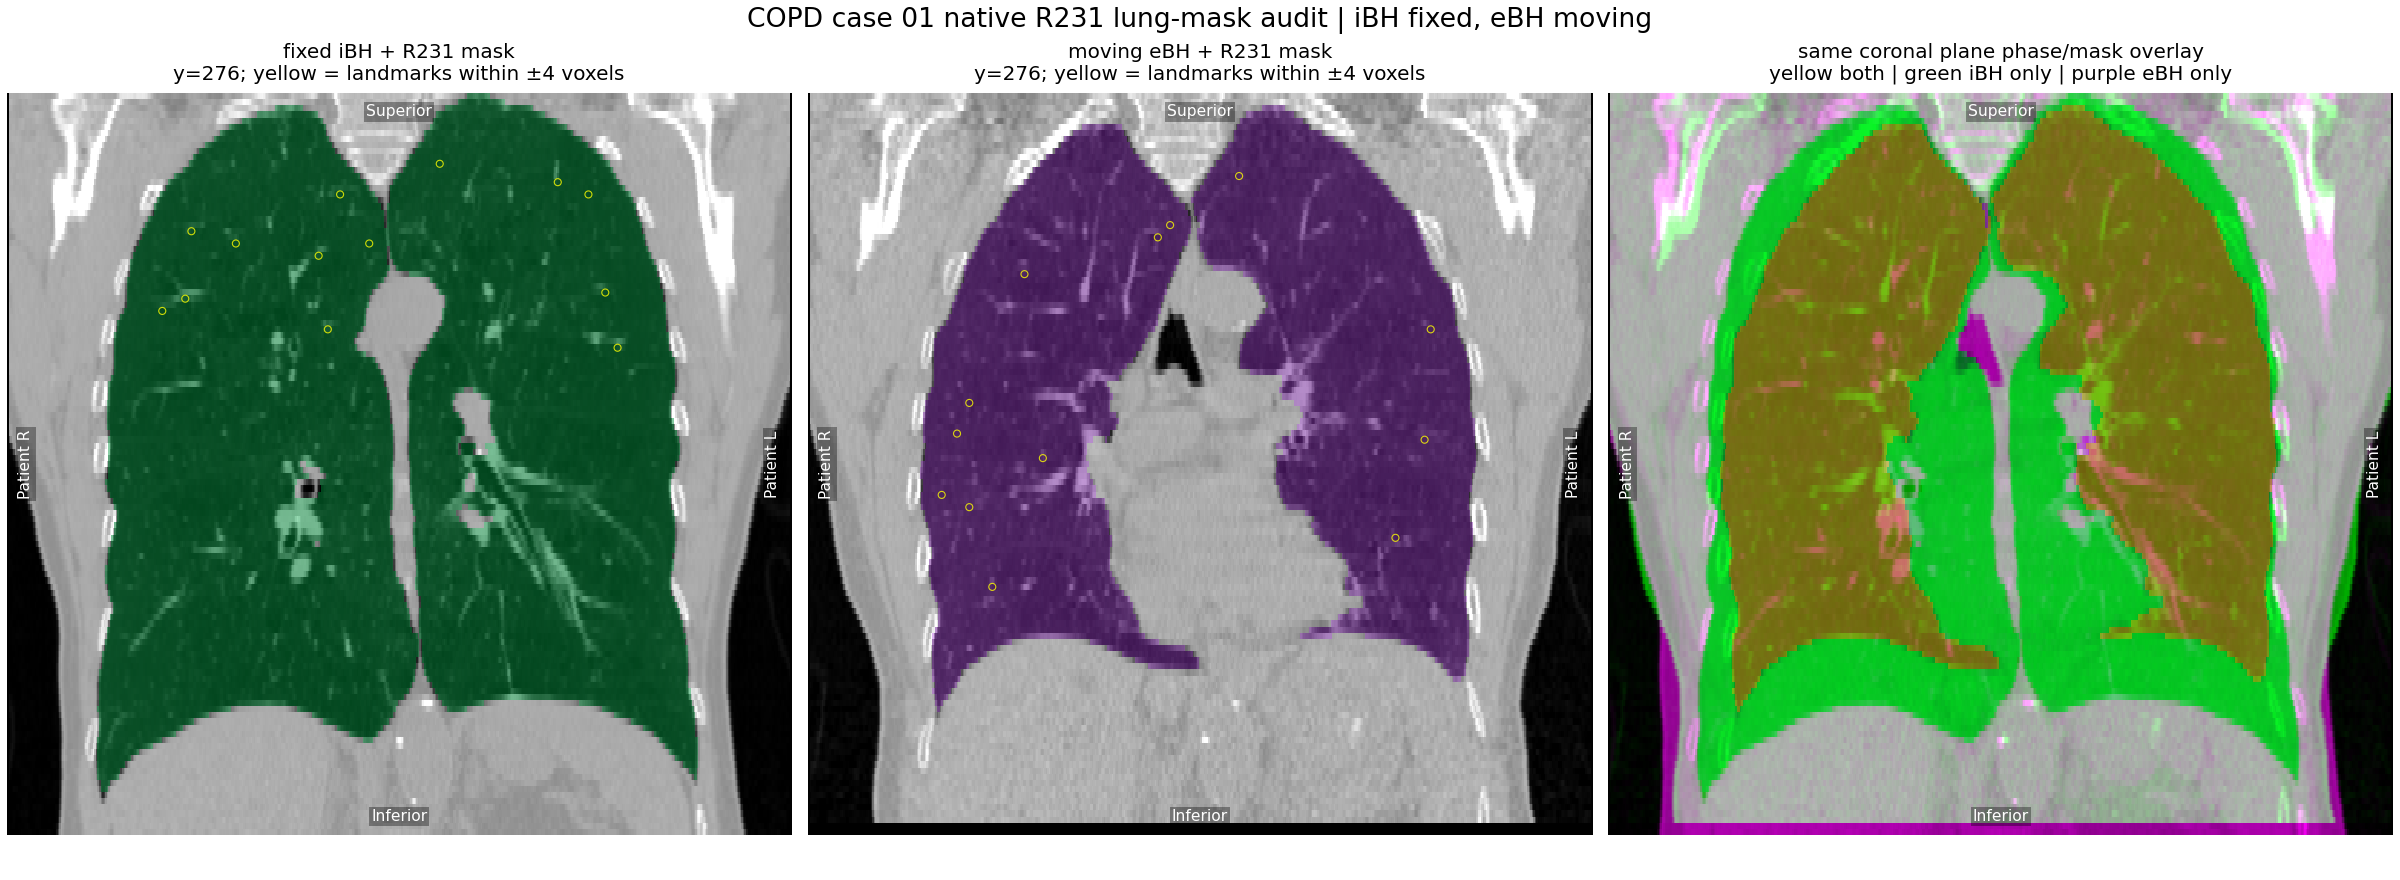

### COPD case 02

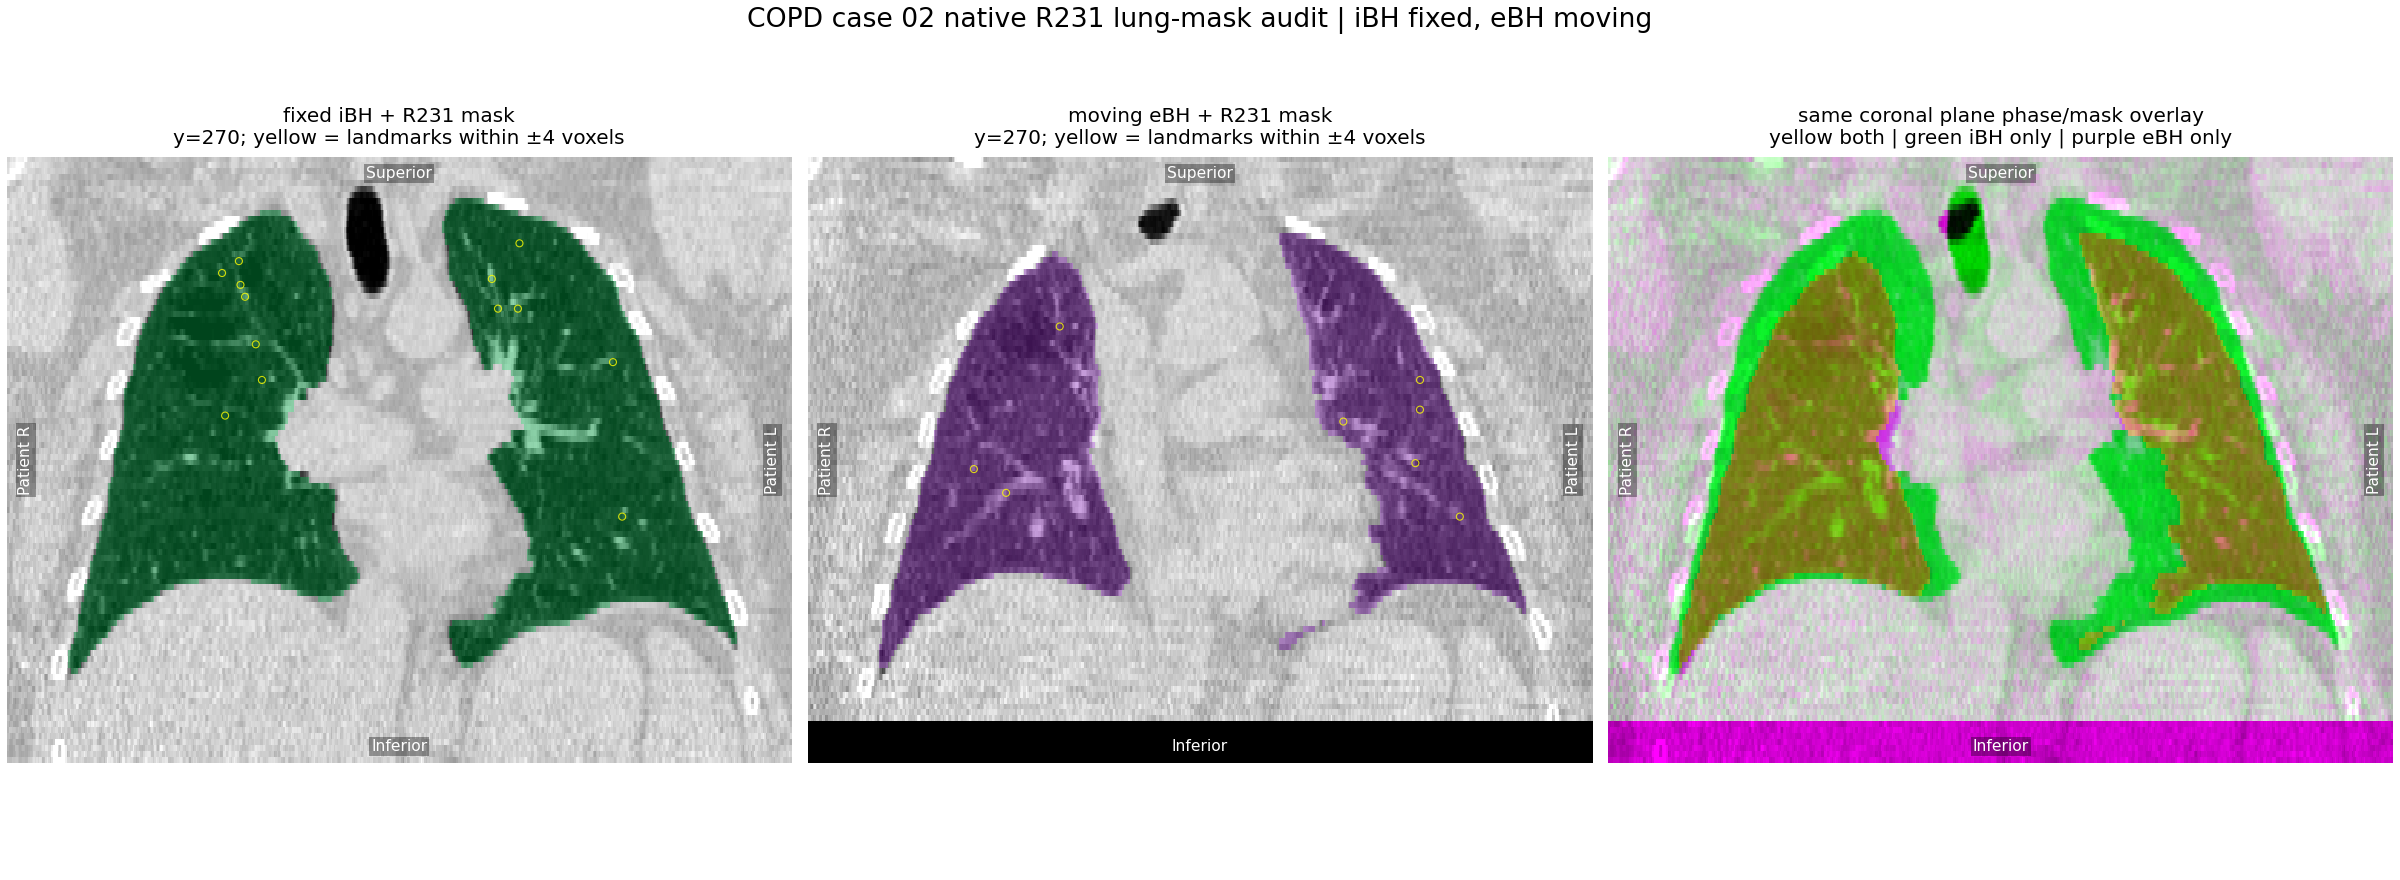

### COPD case 03

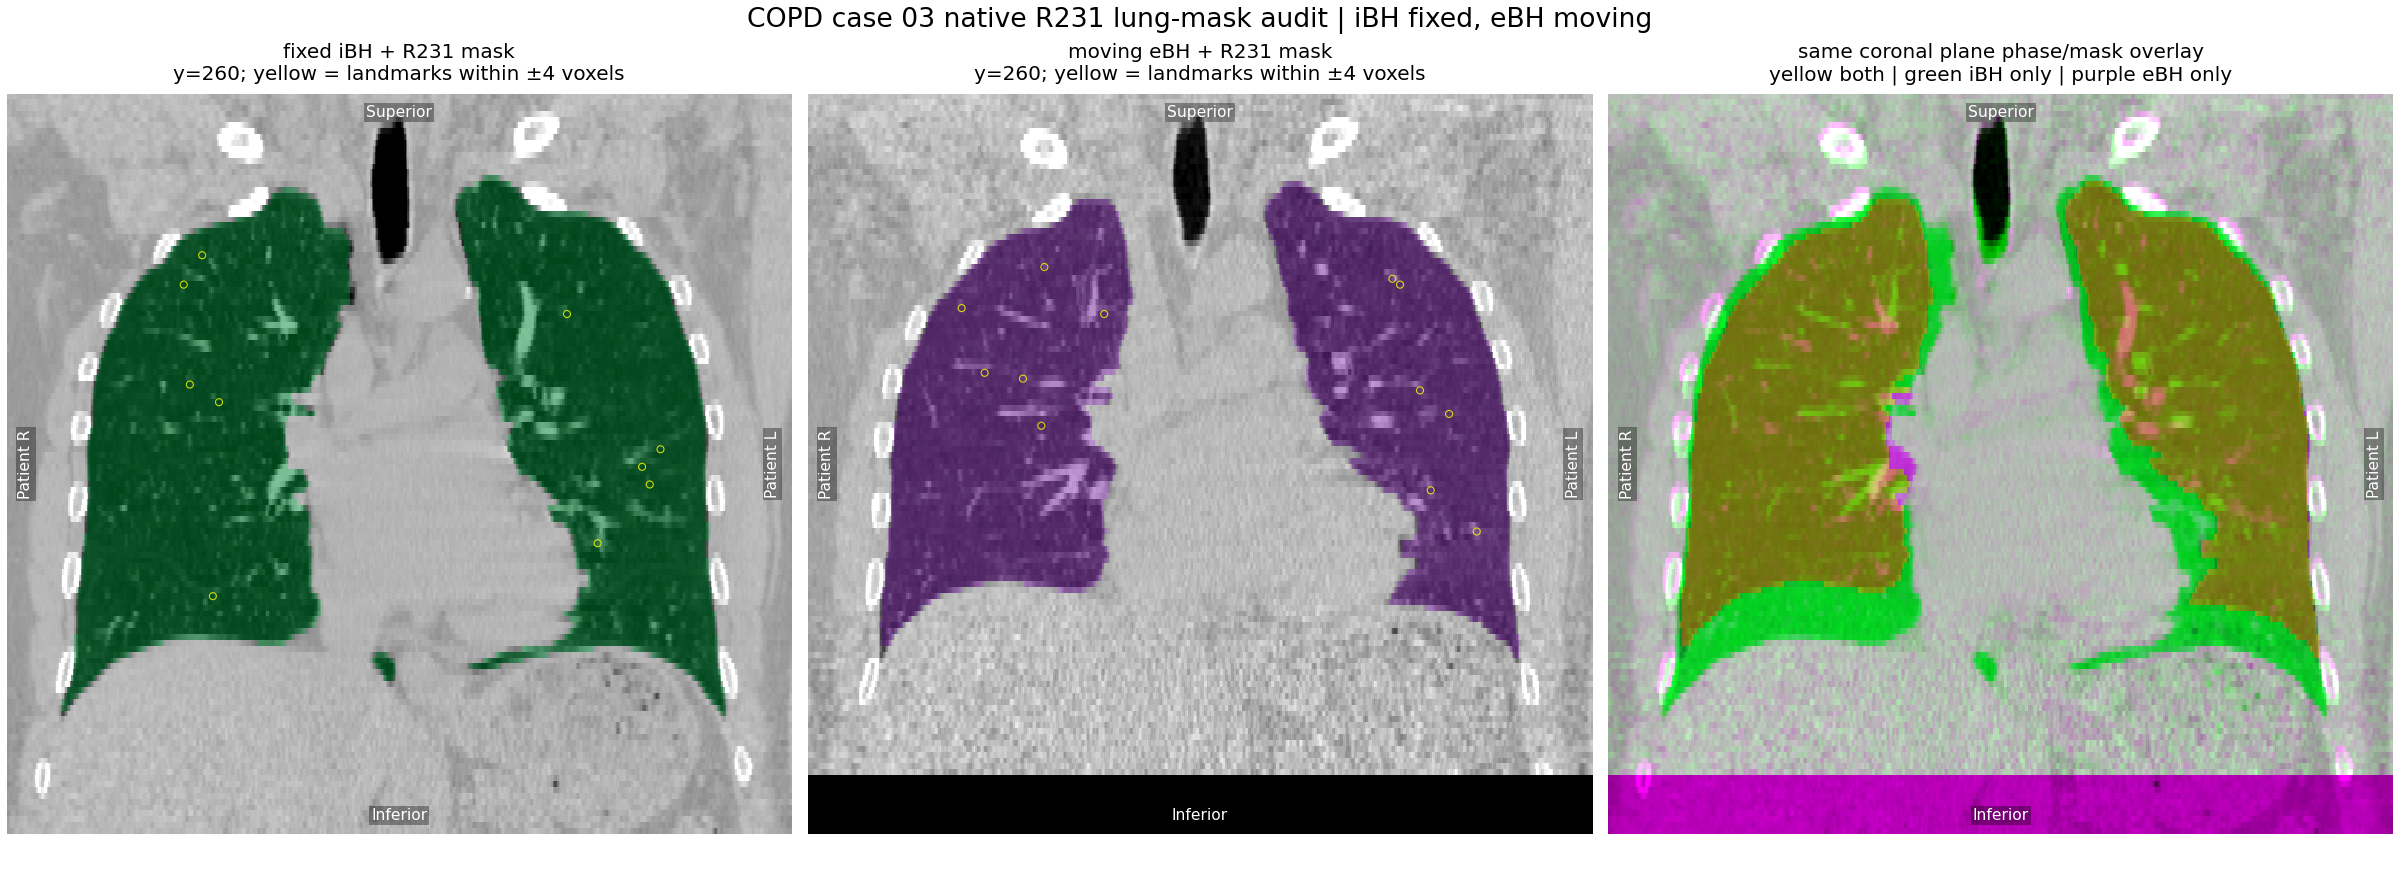

### COPD case 04

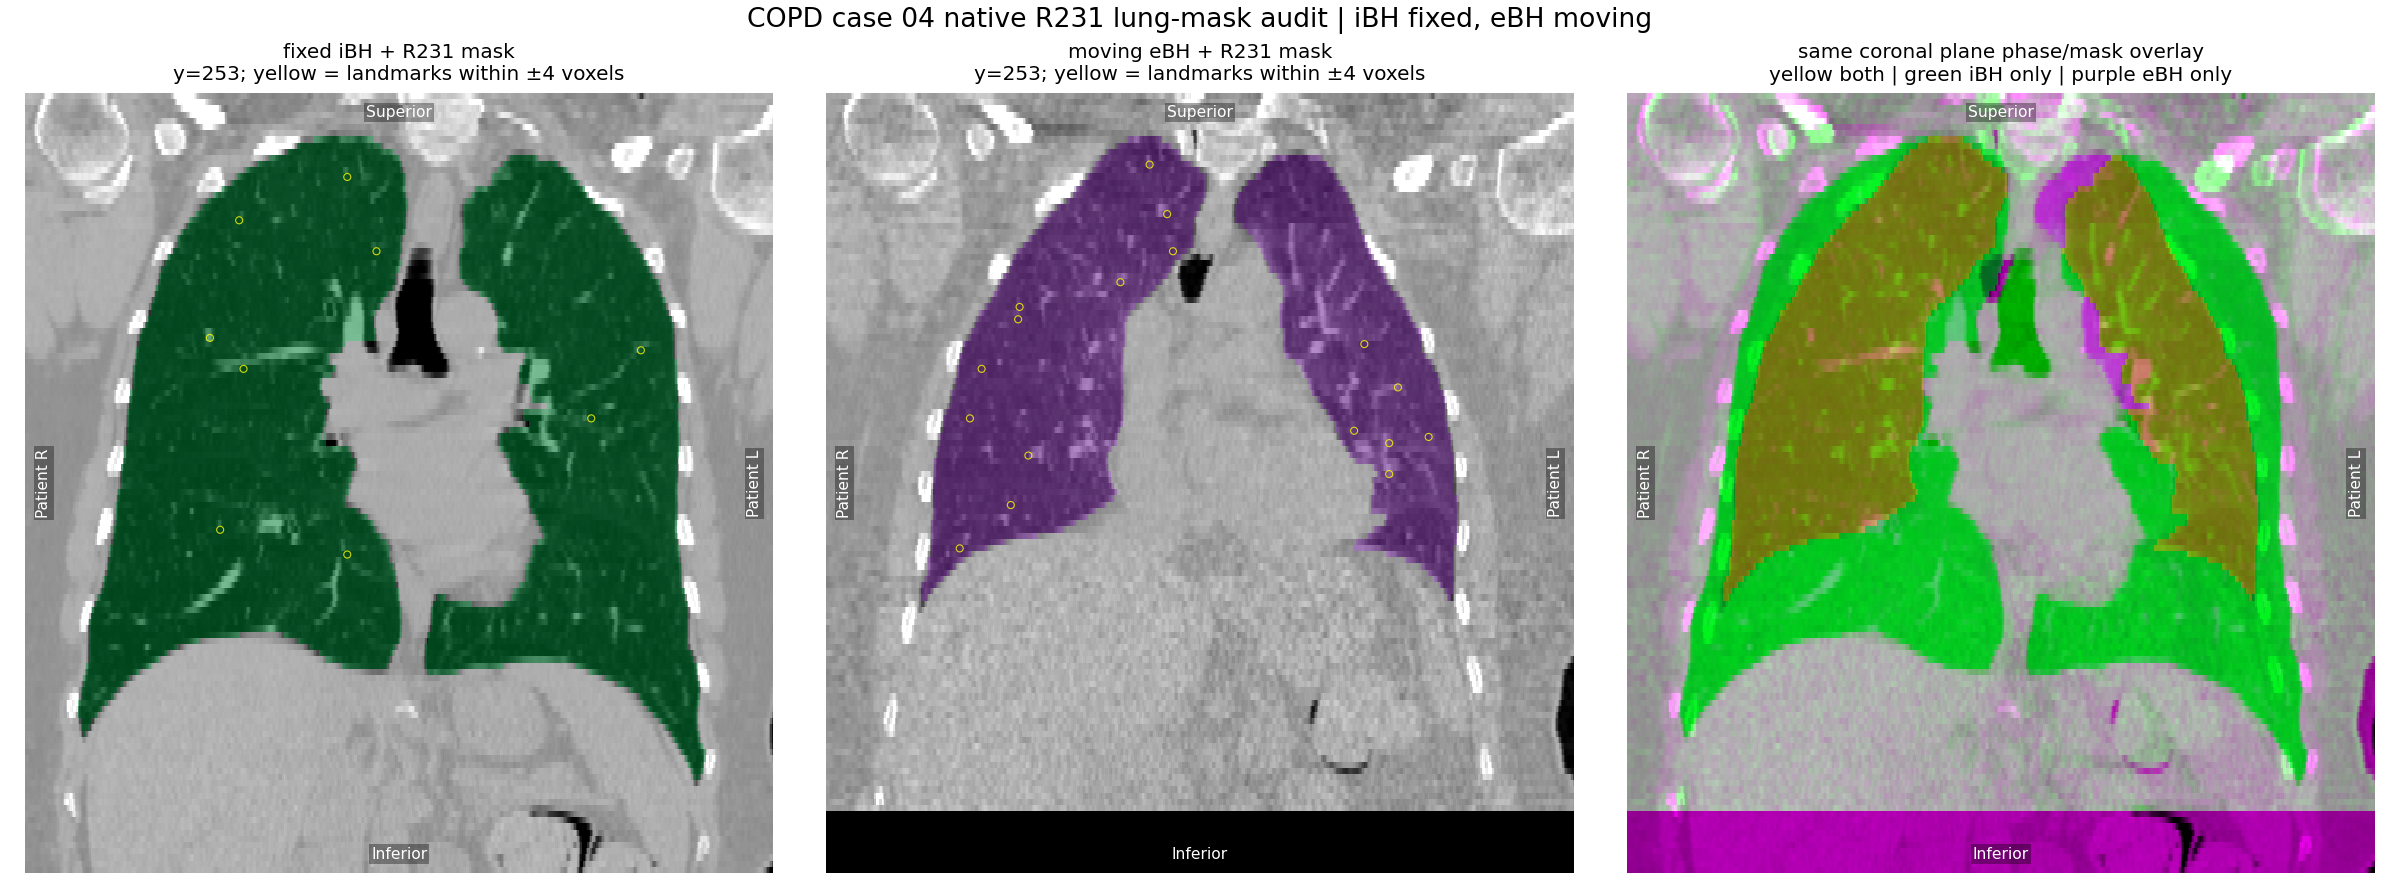

### COPD case 05

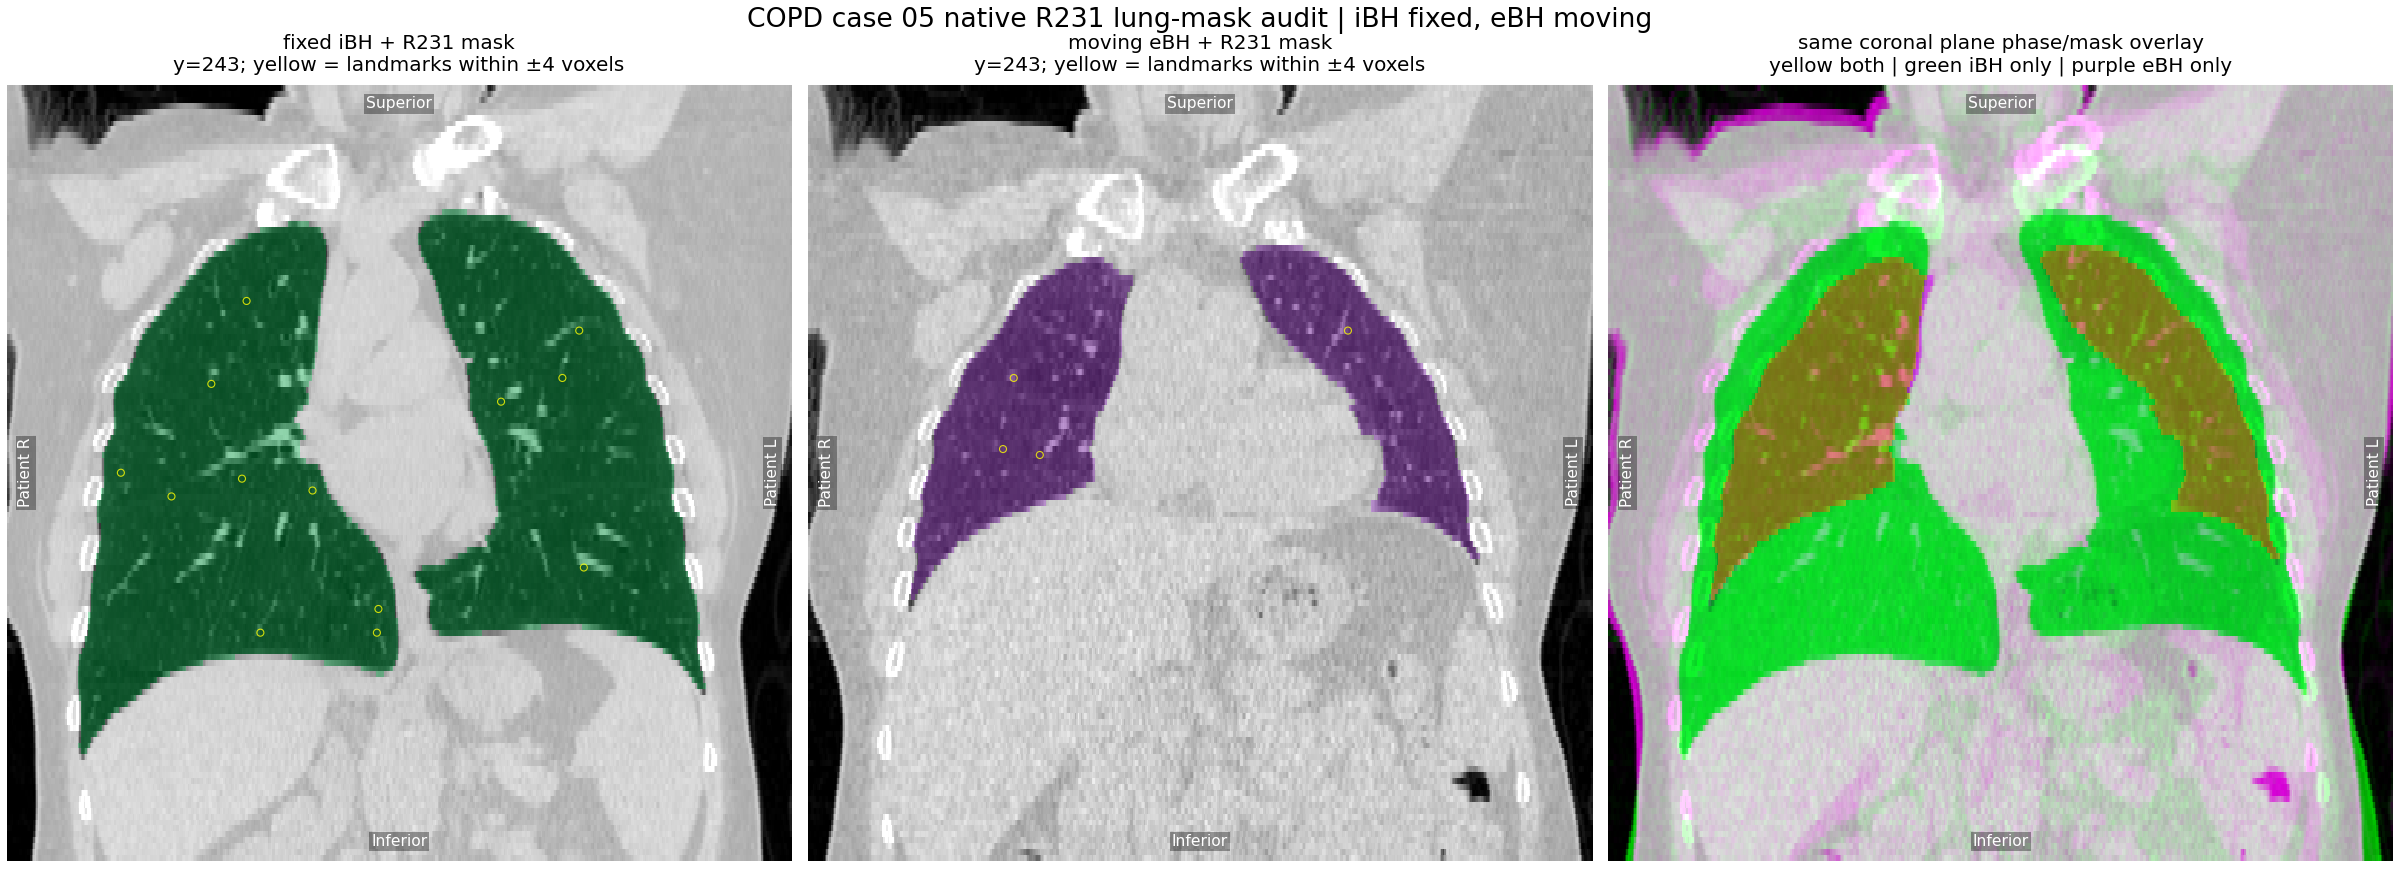

### COPD case 06

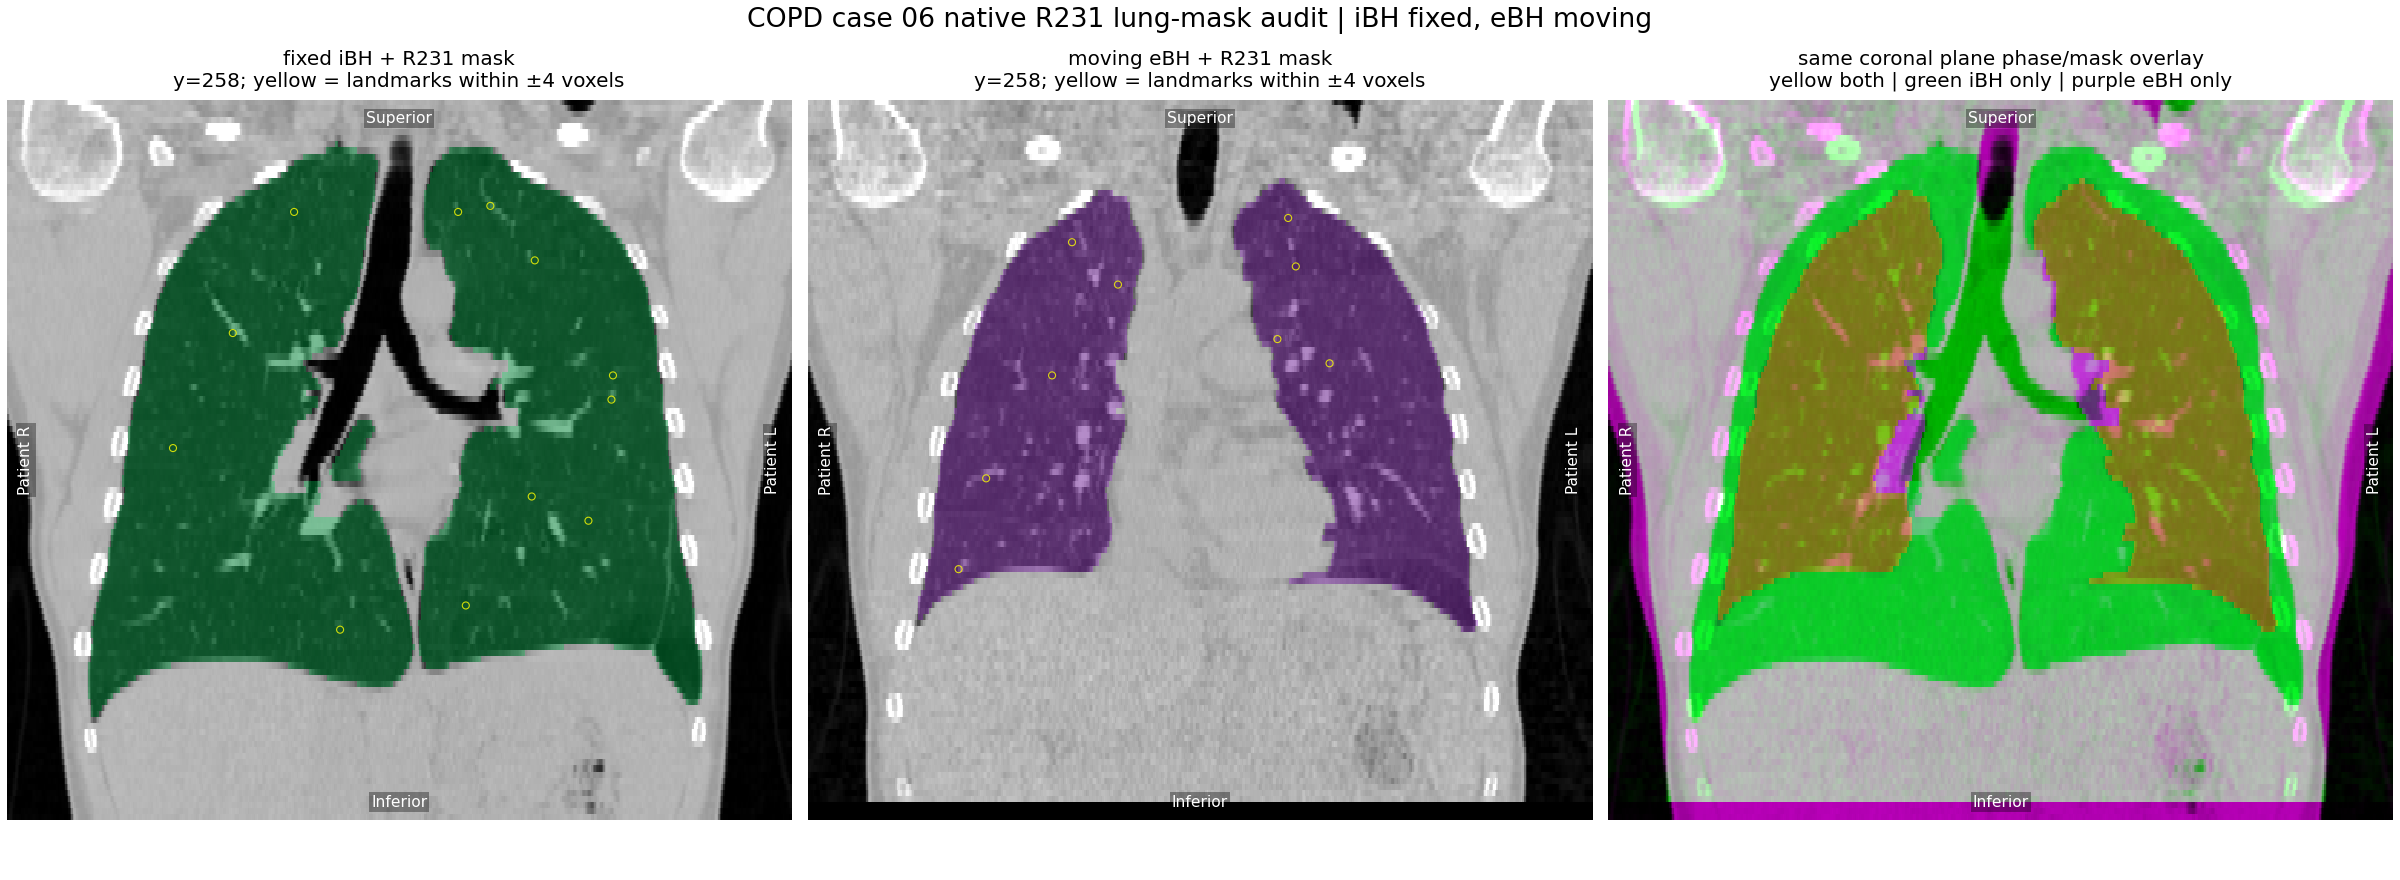

### COPD case 07

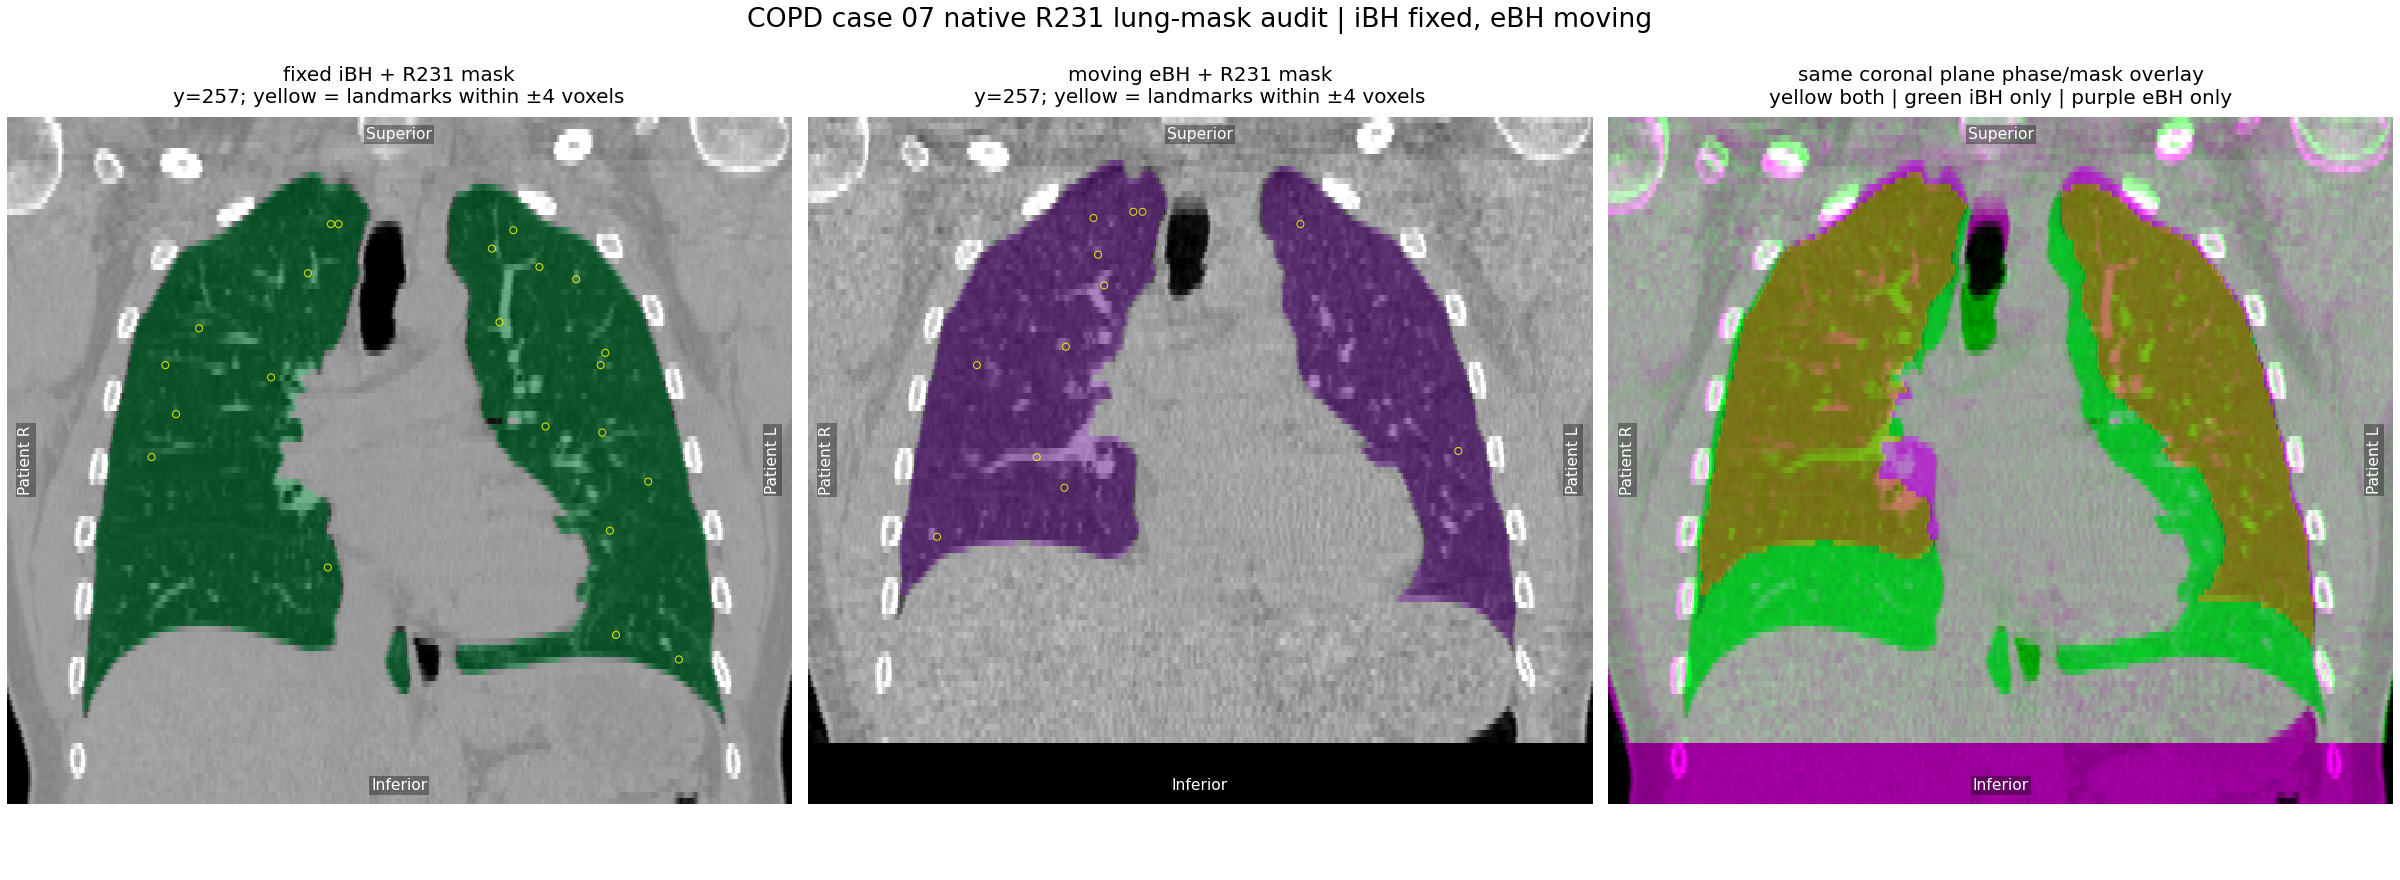

### COPD case 08

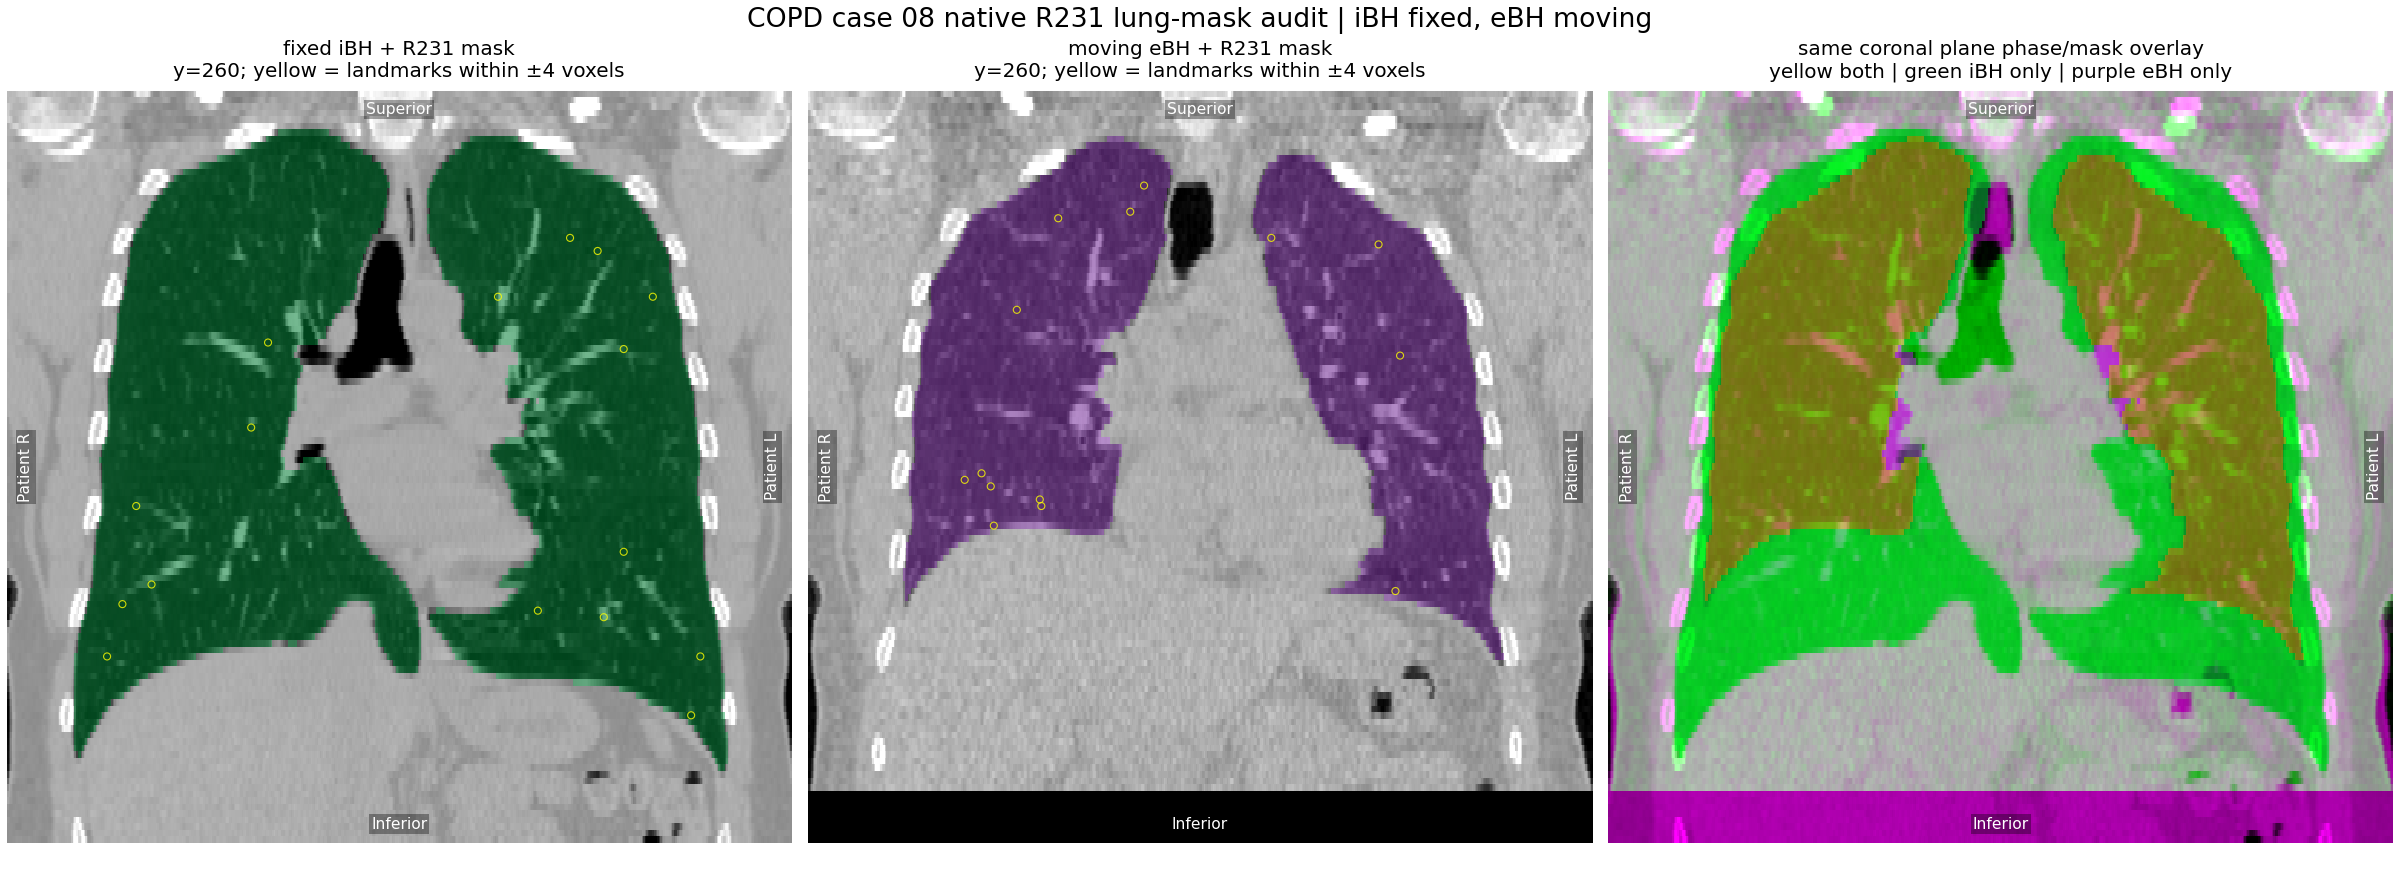

### COPD case 09

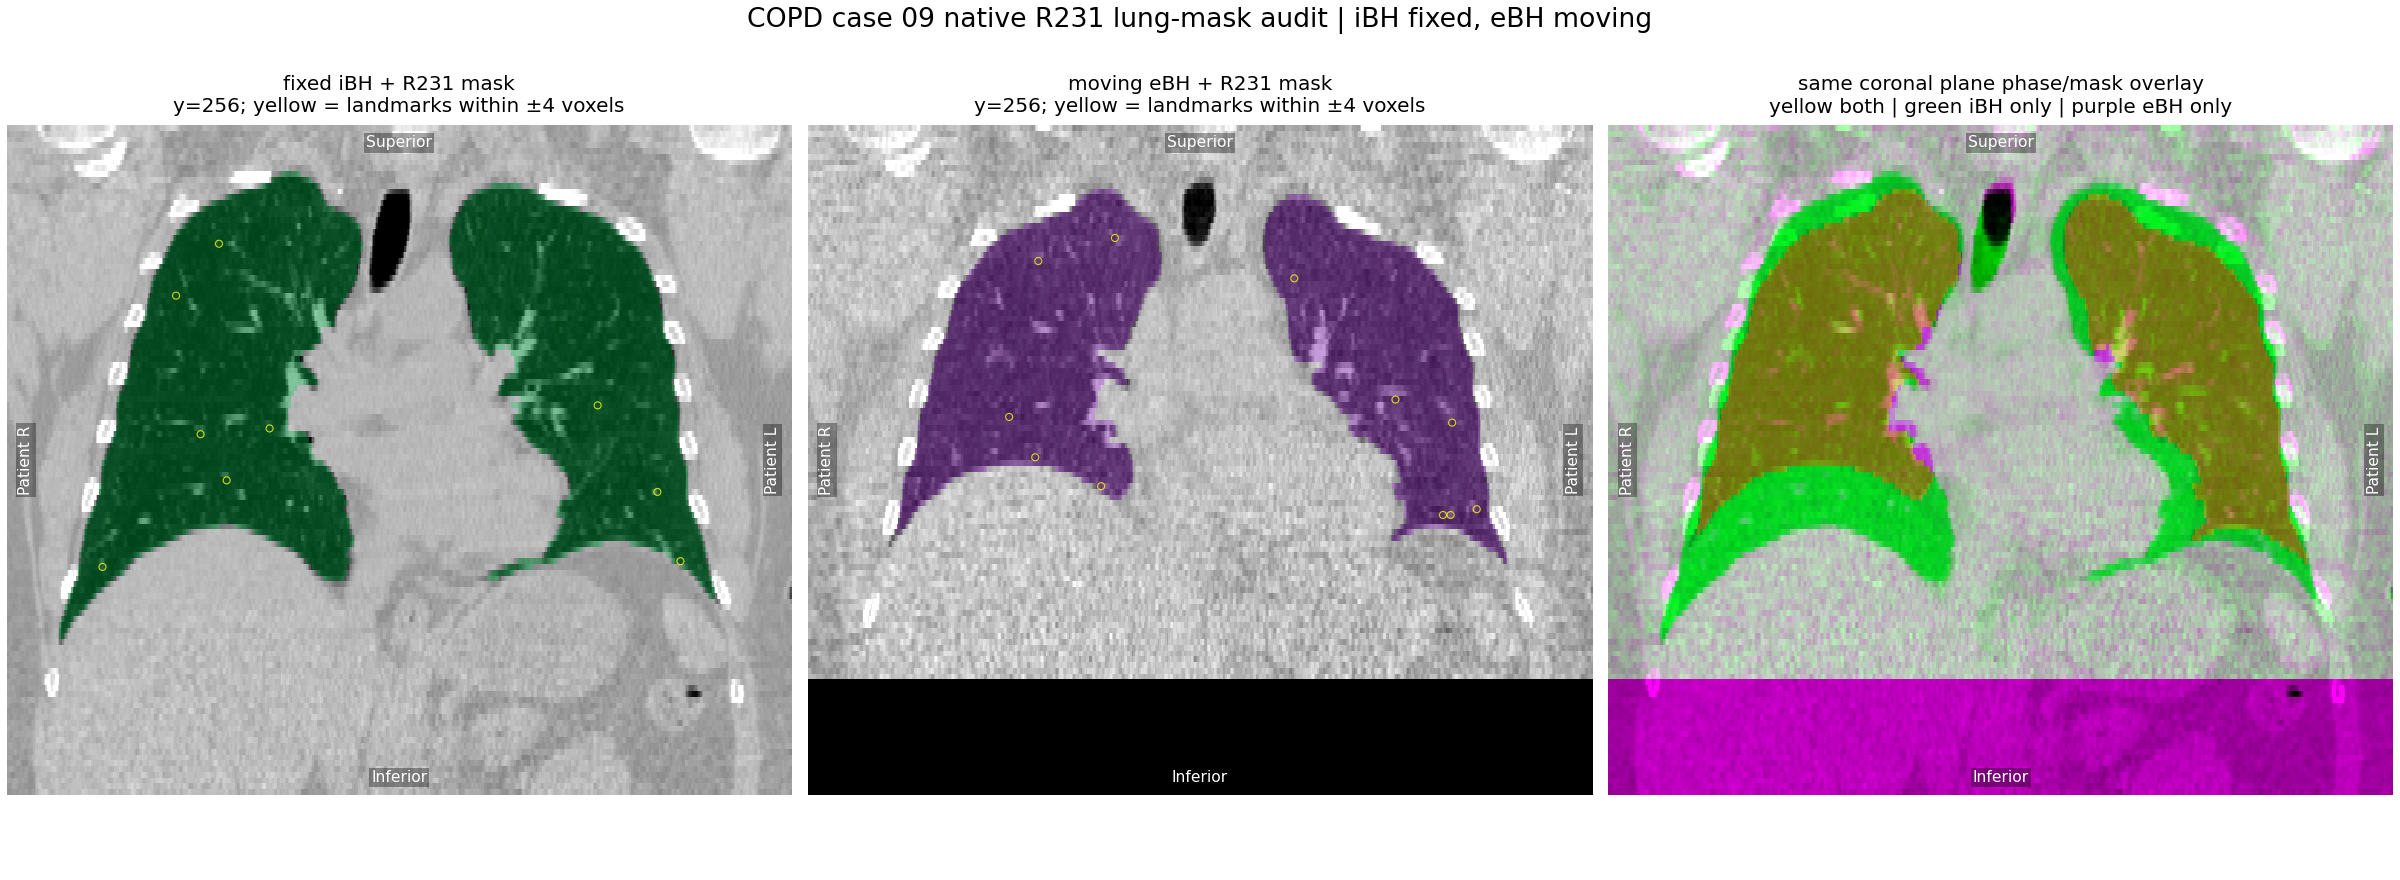

### COPD case 10

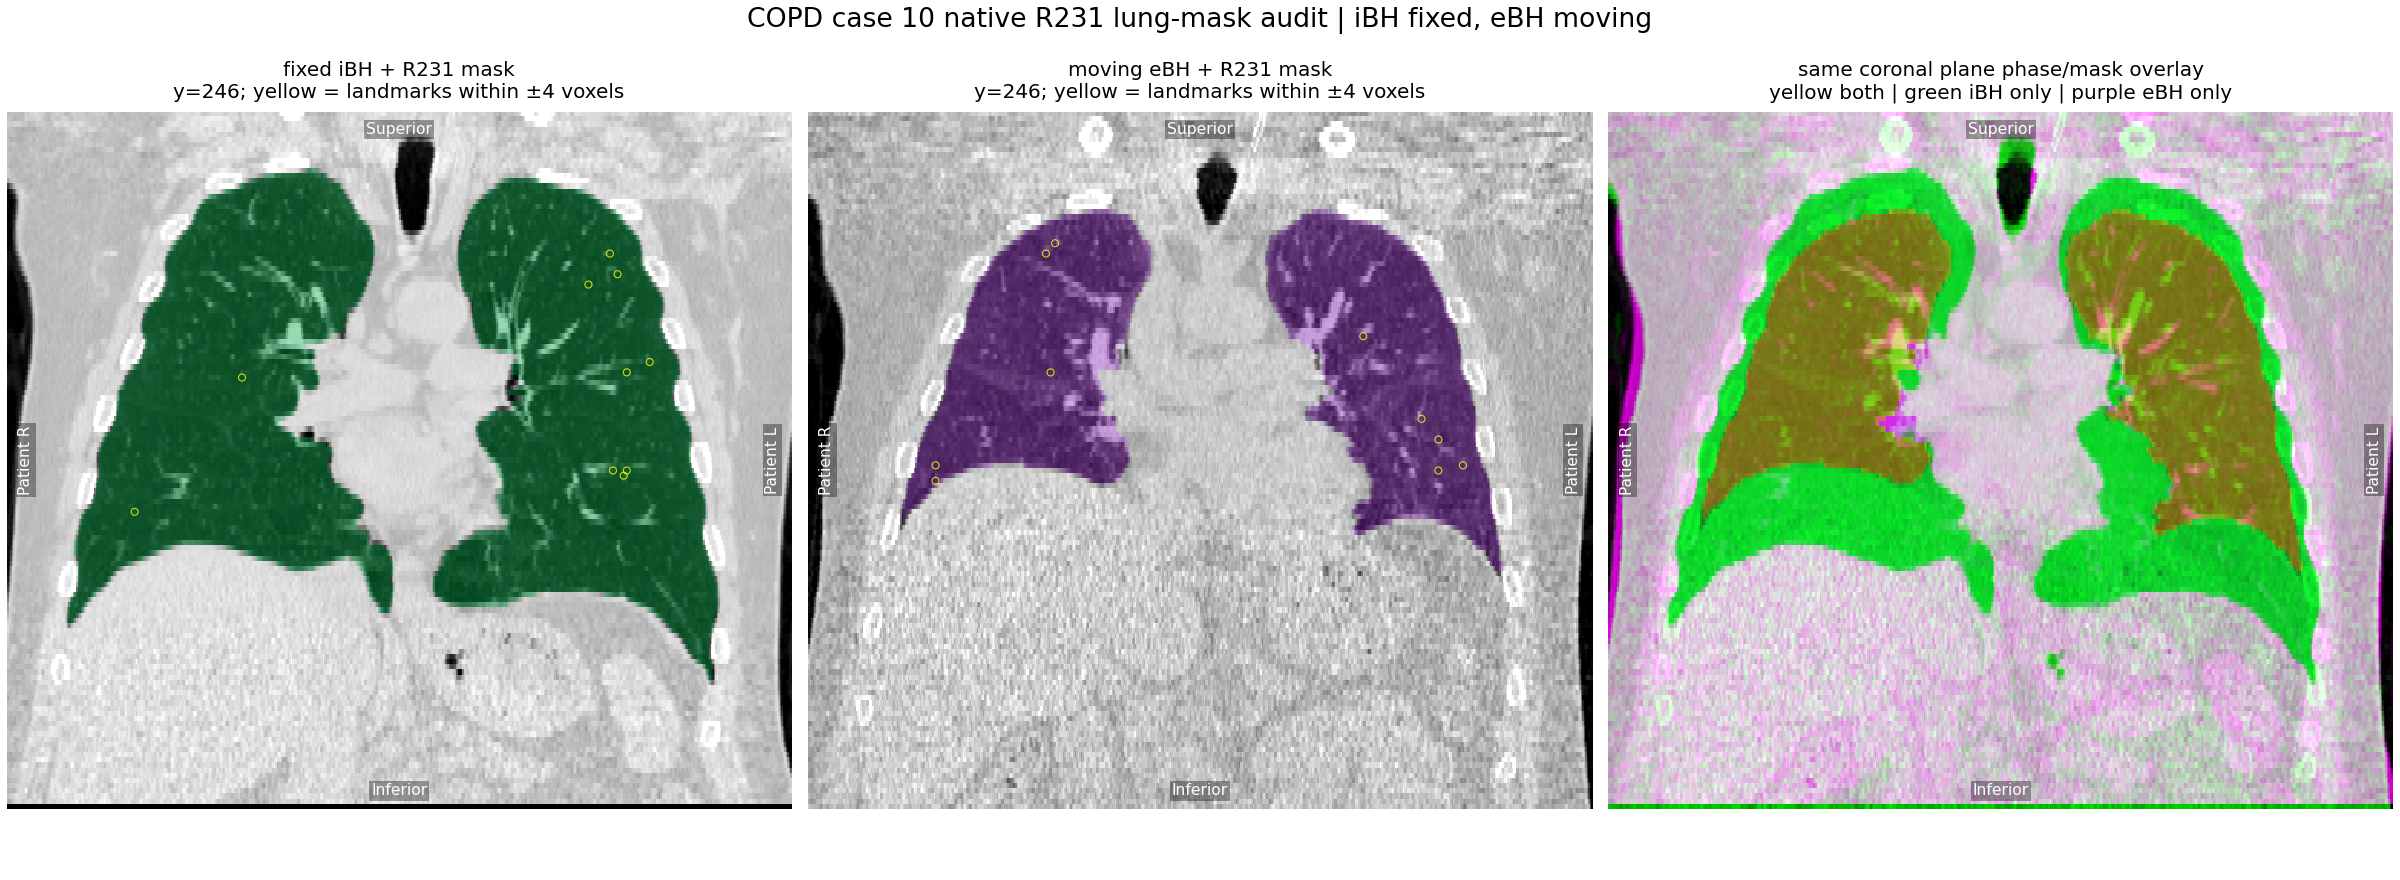

,case,figure,y_index
0,01,outputs/data_inspection/lungct_copd_mask_visua...,276
1,02,outputs/data_inspection/lungct_copd_mask_visua...,270
2,03,outputs/data_inspection/lungct_copd_mask_visua...,260
3,04,outputs/data_inspection/lungct_copd_mask_visua...,253
4,05,outputs/data_inspection/lungct_copd_mask_visua...,243
5,06,outputs/data_inspection/lungct_copd_mask_visua...,258
6,07,outputs/data_inspection/lungct_copd_mask_visua...,257
7,08,outputs/data_inspection/lungct_copd_mask_visua...,260
8,09,outputs/data_inspection/lungct_copd_mask_visua...,256
9,10,outputs/data_inspection/lungct_copd_mask_visua...,246


In [5]:
saved_figures = []

for cid in CASE_IDS:
    payload = case_payloads[cid]
    case = payload['case']
    fixed = payload['fixed']
    moving = payload['moving']
    fixed_mask = payload['fixed_mask']
    moving_mask = payload['moving_mask']
    fixed_lm = payload['fixed_lm']
    moving_lm = payload['moving_lm']
    y_idx = bbox_center_y(fixed_mask, moving_mask, fixed.shape)
    spacing = tuple(float(v) for v in case.spacing_zyx)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), constrained_layout=True)
    fig.suptitle(f'COPD case {cid:02d} native R231 lung-mask audit | iBH fixed, eBH moving', fontsize=12)
    draw_coronal_mask_panel(axes[0], fixed, fixed_mask, fixed_lm, y_idx, spacing, 'fixed iBH + R231 mask', mask_cmap_fixed)
    draw_coronal_mask_panel(axes[1], moving, moving_mask, moving_lm, y_idx, spacing, 'moving eBH + R231 mask', mask_cmap_moving)
    draw_phase_difference_panel(axes[2], fixed, moving, fixed_mask, moving_mask, y_idx, spacing, 'same coronal plane phase/mask overlay')

    fig_path = FIGURE_DIR / f'copd_case{cid:02d}_ibh_ebh_lungmask_coronal.png'
    fig.savefig(fig_path, dpi=160)
    saved_figures.append({'case': f'{cid:02d}', 'figure': str(fig_path.relative_to(REPO_ROOT)), 'y_index': int(y_idx)})
    display(Markdown(f'### COPD case {cid:02d}'))
    display(Image(filename=str(fig_path), width=1100))
    plt.close(fig)

fig_df = pd.DataFrame(saved_figures)
fig_df.to_csv(OUT_DIR / 'lungct_copd_mask_visual_audit_figures.csv', index=False)
write_json(OUT_DIR / 'lungct_copd_mask_visual_audit_figures.json', saved_figures)
display(fig_df)
